# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Zhabyan Rafnan Nur Qohharsya
- **Email:** zhabyanrafnann@gmail.com
- **ID Dicoding:** zhabyan_rafnan_nur_qohharsya_WmTL

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada jam berapa saja permintaan sewa sepeda mencapai puncaknya pada hari kerja sepanjang periode 2011–2012, dan berapa persen selisih rata-rata penyewaan antara jam puncak dan jam paling sepi, agar tim operasional dapat mengatur jadwal pengembalian (*repositioning*) armada?
- **Pertanyaan 2:** Bagaimana pengaruh kondisi cuaca terhadap rata-rata jumlah penyewaan harian sepanjang 2011–2012, khususnya berapa persen penurunan penyewaan pada hari hujan ringan dibandingkan hari cerah, agar tim bisnis dapat menyusun strategi promosi saat cuaca buruk?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

## Data Wrangling

### Gathering Data

#### Load df_day (day.csv) dan df_hour (hour.csv)

In [2]:
day_df = pd.read_csv('day.csv')
hour_df = pd.read_csv('hour.csv')

print('day_df:', day_df.shape)
print('hour_df:', hour_df.shape)
day_df.head()

day_df: (731, 16)
hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Dataset terdiri dari dua file: `day.csv` (731 baris, data harian) dan `hour.csv` (17.379 baris, data per jam) yang mencakup periode **1 Januari 2011 – 31 Desember 2012** (2 tahun).
- Kedua tabel memiliki kolom yang sama, kecuali `hour.csv` yang memiliki kolom tambahan `hr` (jam ke-0 sampai 23).
- Fitur cuaca dan suhu (`temp`, `atemp`, `hum`, `windspeed`) sudah dinormalisasi dalam rentang 0–1, sehingga satuan aslinya perlu dikembalikan saat interpretasi bisnis.

### Assessing Data

#### Identifying missing value, invalid value, dan outlier

In [3]:
# 1. Cek missing value & duplikat
print('Missing value day_df:')
print(day_df.isna().sum())
print('\nMissing value hour_df:')
print(hour_df.isna().sum())

print('\nJumlah duplikat:', day_df.duplicated().sum(), '/', hour_df.duplicated().sum())

# 2. Cek invalid value: kelembapan (hum) bernilai 0
print('\nBaris dengan hum == 0 -> day_df:', (day_df['hum'] == 0).sum(),
      '| hour_df:', (hour_df['hum'] == 0).sum())

# 3. Cek outlier dengan metode IQR
def count_outliers(df, col):
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((df[col] < low) | (df[col] > high)).sum())

print('\nOutlier windspeed -> day_df:', count_outliers(day_df, 'windspeed'),
      '| hour_df:', count_outliers(hour_df, 'windspeed'))
print('Outlier cnt (hour_df):', count_outliers(hour_df, 'cnt'))

Missing value day_df:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Missing value hour_df:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Jumlah duplikat: 0 / 0

Baris dengan hum == 0 -> day_df: 1 | hour_df: 22

Outlier windspeed -> day_df: 13 | hour_df: 342
Outlier cnt (hour_df): 505


**Steps to Take:**
- **Invalid value (`hum` = 0):** 1 baris di `day.csv` dan 22 baris di `hour.csv` memiliki kelembapan 0% yang secara fisik hampir tidak mungkin → **imputasi dengan median kelembapan per musim**.
- **Outlier `windspeed`:** 13 outlier di `day.csv` dan 342 outlier di `hour.csv` (metode IQR) → **biarkan (tidak dihapus)** karena cuaca buruk/angin kencang memang bagian dari kondisi bisnis yang valid; cukup diberi catatan saat analisis.
- **Outlier `cnt` pada `hour.csv` (505 baris):** mencerminkan lonjakan permintaan alami pada jam sibuk → **dipertahankan**, justru menjadi fokus analisis pertanyaan bisnis.
- **Duplikat & missing value:** tidak ditemukan pada kedua dataset → tidak diperlukan penanganan khusus.

**Insight:** (Opsional)
- Kualitas data kedua dataset tergolong baik: tidak ada *missing value* dan tidak ada *duplicate rows*.
- Masalah utama yang ditemukan adalah **invalid value pada `hum`** (nilai 0%) dan **outlier pada `windspeed`/`cnt`**, sehingga tahap cleaning cukup ringan dan tidak mengubah struktur dataset.

### Cleaning Data

#### Fixing invalid value & menyiapkan kolom kategorikal

In [4]:
# 1. Fixing invalid value: imputasi hum == 0 dengan median hum per musim
season_median_hum = day_df.groupby('season')['hum'].median()
day_df['hum'] = day_df.apply(
    lambda r: season_median_hum[r['season']] if r['hum'] == 0 else r['hum'], axis=1)

season_median_hum_h = hour_df.groupby('season')['hum'].median()
hour_df['hum'] = hour_df.apply(
    lambda r: season_median_hum_h[r['season']] if r['hum'] == 0 else r['hum'], axis=1)

# 2. Dekode kolom kategorikal agar mudah dibaca
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map = {1: 'Cerah', 2: 'Kabut', 3: 'Hujan Ringan', 4: 'Hujan Lebat'}

for df in (day_df, hour_df):
    df['season_name'] = df['season'].map(season_map)
    df['weather_name'] = df['weathersit'].map(weather_map)

print('hum == 0 tersisa -> day_df:', (day_df['hum'] == 0).sum(),
      '| hour_df:', (hour_df['hum'] == 0).sum())
print('Jumlah baris tetap:', day_df.shape[0], '/', hour_df.shape[0])
day_df.head()

hum == 0 tersisa -> day_df: 0 | hour_df: 0
Jumlah baris tetap: 731 / 17379


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_name,weather_name
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,Spring,Kabut
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,Spring,Kabut
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,Spring,Cerah
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562,Spring,Cerah
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600,Spring,Cerah


**Insight:** (Opsional)
- Setelah imputasi, tidak ada lagi nilai `hum` = 0; jumlah baris tetap **731 (day)** dan **17.379 (hour)** sehingga tidak ada data yang hilang.
- Kolom kategorikal (`season`, `weathersit`, `yr`, `mnth`, `weekday`) didekode ke label yang mudah dibaca agar hasil grouping dan visualisasi lebih informatif.

## Visualization & Explanatory Analysis

Dua visualasi utama dibuat untuk menjawab kedua pertanyaan bisnis. Prinsip desain yang diterapkan:

- **Judul yang informatif** — setiap grafik menyebutkan apa yang ditunjukkan dan periode datanya.
- **Label sumbu lengkap** — pembaca tidak perlu menebak satuan (sepeda/jam atau sepeda/hari).
- **Anotasi nilai** — angka kunci langsung ditandai pada grafik agar insight terbaca tanpa merujuk tabel.
- **Warna bermakna** — perbandingan dua kelompok (hari kerja vs akhir pekan) memakai warna kontras yang konsisten.
- **Sumber data transparan** — *Bike Sharing Dataset* (Fanaee-T & Gama, 2014), periode 2011–2012.

## Exploratory Data Analysis (EDA)

### Explore distribusi & pola permintaan berdasarkan jam, hari kerja, cuaca, dan musim

In [5]:
# Ringkasan statistik harian
print(day_df[['cnt', 'casual', 'registered', 'temp', 'atemp', 'hum', 'windspeed']].describe().round(0))

# Rata-rata penyewaan per tahun, musim, dan tipe hari
print('\nTotal per tahun:')
print(day_df.groupby('yr')['cnt'].sum())

print('\nRata-rata per musim:')
print(day_df.groupby('season_name')['cnt'].mean().round(0))

# Kontribusi registered vs casual
total_registered = day_df['registered'].sum()
total_cnt = day_df['cnt'].sum()
print(f'\nRegistered share: {100 * total_registered / total_cnt:.1f}%')

# Korelasi fitur cuaca terhadap jumlah penyewaan
print('\nKorelasi dengan cnt:')
print(day_df[['atemp', 'hum', 'windspeed']].corrwith(day_df['cnt']).round(2))

          cnt  casual  registered   temp  atemp    hum  windspeed
count   731.0   731.0       731.0  731.0  731.0  731.0      731.0
mean   4504.0   848.0      3656.0    0.0    0.0    1.0        0.0
std    1937.0   687.0      1560.0    0.0    0.0    0.0        0.0
min      22.0     2.0        20.0    0.0    0.0    0.0        0.0
25%    3152.0   316.0      2497.0    0.0    0.0    1.0        0.0
50%    4548.0   713.0      3662.0    0.0    0.0    1.0        0.0
75%    5956.0  1096.0      4776.0    1.0    1.0    1.0        0.0
max    8714.0  3410.0      6946.0    1.0    1.0    1.0        1.0

Total per tahun:
yr
0    1243103
1    2049576
Name: cnt, dtype: int64

Rata-rata per musim:
season_name
Fall      5644.0
Spring    2604.0
Summer    4992.0
Winter    4728.0
Name: cnt, dtype: float64

Registered share: 81.2%

Korelasi dengan cnt:
atemp        0.63
hum         -0.11
windspeed   -0.23
dtype: float64


**Insight:** (Opsional)
- Rata-rata penyewaan harian adalah **4.504 sepeda/hari**, dengan total 2011 sebesar **1.243.103** dan 2012 sebesar **2.049.576** (*grow* **+64,9% YoY**).
- **81,2%** total penyewaan berasal dari pengguna *registered* (langganan), sisanya 18,8% dari pengguna *casual*.
- Musim **Fall** memiliki rata-rata tertinggi (**5.644/hari**) dan **Spring** terendah (**2.604/hari**).
- `atemp` berkorelasi positif sedang dengan `cnt` (**0.63**), sedangkan `windspeed` berkorelasi negatif lemah (**-0.23**).

### Pertanyaan 1:
Pada jam berapa saja permintaan sewa sepeda mencapai puncaknya pada hari kerja sepanjang periode 2011–2012, dan berapa persen selisih rata-rata penyewaan antara jam puncak dan jam paling sepi, agar tim operasional dapat mengatur jadwal pengembalian (*repositioning*) armada?

Puncak hari kerja: jam 17 -> 525 sepeda/jam
Terendah hari kerja: jam 3 -> 5 sepeda/jam
Selisih puncak vs terendah: 10528 %
Puncak akhir pekan: jam 13 -> 373 sepeda/jam


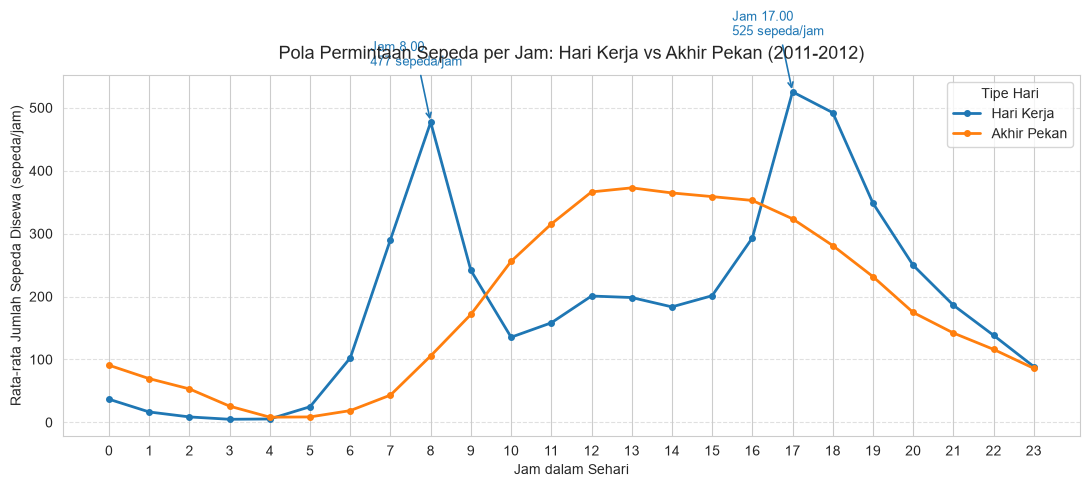

In [6]:
# Rata-rata penyewaan per jam: hari kerja vs akhir pekan
working = hour_df[hour_df['workingday'] == 1].groupby('hr')['cnt'].mean()
non_working = hour_df[hour_df['workingday'] == 0].groupby('hr')['cnt'].mean()

print('Puncak hari kerja: jam', working.idxmax(), '->', round(working.max()), 'sepeda/jam')
print('Terendah hari kerja: jam', working.idxmin(), '->', round(working.min()), 'sepeda/jam')
print('Selisih puncak vs terendah:',
      round(100 * (working.max() - working.min()) / working.min()), '%')
print('Puncak akhir pekan: jam', non_working.idxmax(), '->', round(non_working.max()), 'sepeda/jam')

# Visualisasi: line chart pola permintaan harian
plt.figure(figsize=(11, 5))
plt.plot(working.index, working.values, marker='o', markersize=4,
         linewidth=2, color='#1f77b4', label='Hari Kerja')
plt.plot(non_working.index, non_working.values, marker='o', markersize=4,
         linewidth=2, color='#ff7f0e', label='Akhir Pekan')

# Anotasi dua puncak hari kerja
for hr in [8, 17]:
    plt.annotate(f'Jam {hr}.00\n{int(working[hr])} sepeda/jam',
                 xy=(hr, working[hr]), xytext=(hr - 1.5, working[hr] + 90),
                 fontsize=9, color='#1f77b4',
                 arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.2))

plt.title('Pola Permintaan Sepeda per Jam: Hari Kerja vs Akhir Pekan (2011-2012)', fontsize=13, pad=12)
plt.xlabel('Jam dalam Sehari')
plt.ylabel('Rata-rata Jumlah Sepeda Disewa (sepeda/jam)')
plt.xticks(range(0, 24))
plt.legend(title='Tipe Hari')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Pertanyaan 2:
Bagaimana pengaruh kondisi cuaca terhadap rata-rata jumlah penyewaan harian sepanjang 2011–2012, khususnya berapa persen penurunan penyewaan pada hari hujan ringan dibandingkan hari cerah, agar tim bisnis dapat menyusun strategi promosi saat cuaca buruk?

                mean  count
weather_name               
Cerah         4877.0    463
Hujan Ringan  1803.0     21
Kabut         4036.0    247
Cerah: 0.0% vs hari cerah
Hujan Ringan: -63.0% vs hari cerah
Kabut: -17.2% vs hari cerah


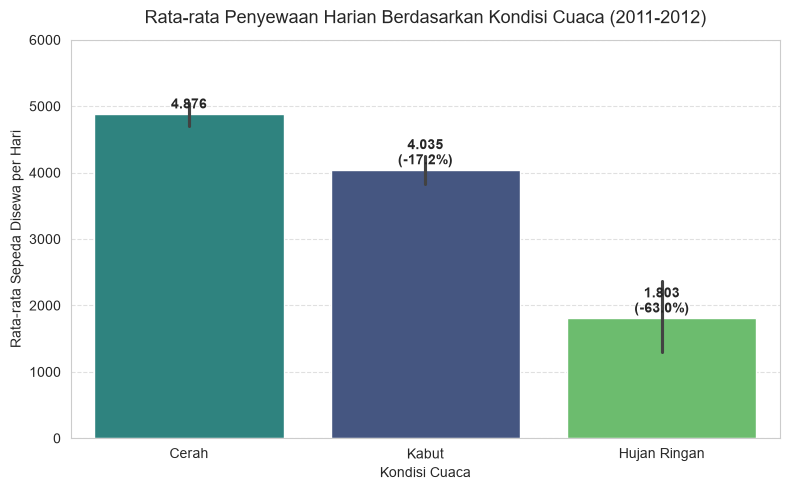

Sumber: Bike Sharing Dataset (Fanaee-T & Gama, 2014)


In [7]:
# Rata-rata penyewaan harian berdasarkan kondisi cuaca
weather_daily = day_df.groupby('weather_name')['cnt'].agg(['mean', 'count']).round(0)
print(weather_daily)

# Persentase penurunan dibandingkan hari cerah
clear = day_df[day_df['weathersit'] == 1]['cnt'].mean()
for name, grp in day_df.groupby('weather_name'):
    print(f'{name}: {100 * (grp["cnt"].mean() - clear) / clear:.1f}% vs hari cerah')

# Visualisasi: bar chart pengaruh cuaca dengan anotasi nilai
plt.figure(figsize=(8, 5))
order = ['Cerah', 'Kabut', 'Hujan Ringan']
ax = sns.barplot(data=day_df, x='weather_name', y='cnt', hue='weather_name',
                 order=order, palette='viridis', legend=False)

# Anotasi nilai rata-rata + persentase penurunan
for i, name in enumerate(order):
    mean_val = day_df.loc[day_df['weather_name'] == name, 'cnt'].mean()
    drop = 100 * (mean_val - clear) / clear
    label = f'{int(mean_val):,}'.replace(',', '.') + f'\n({drop:+.1f}%)' if drop != 0 else f'{int(mean_val):,}'.replace(',', '.')
    ax.text(i, mean_val + 90, label, ha='center', fontsize=10, fontweight='bold')

plt.title('Rata-rata Penyewaan Harian Berdasarkan Kondisi Cuaca (2011-2012)', fontsize=13, pad=12)
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Rata-rata Sepeda Disewa per Hari')
plt.ylim(0, 6000)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print('Sumber: Bike Sharing Dataset (Fanaee-T & Gama, 2014)')

**Insight:** (Opsional)
- **Pertanyaan 1:** Pada hari kerja terdapat dua puncak permintaan gaya komuter, yaitu **pukul 17.00 (rata-rata 525 sepeda/jam)** dan **pukul 08.00 (477 sepeda/jam)**, sementara paling sepi pukul 03.00 (5 sepeda/jam) — puncak lebih dari **100 kali lipat** dibanding jam terendah. Di akhir pekan pola berubah menjadi rekreasi siang hari dengan puncak **pukul 13.00 (373 sepeda/jam)**.
- **Pertanyaan 2:** Rata-rata penyewaan harian turun **17,2%** pada hari berkabut (4.036/hari) dan **63,0%** pada hari hujan ringan (1.803/hari) dibandingkan hari cerah (4.877/hari). Di `day.csv` tidak pernah tercatat hari dengan cuaca sangat buruk (level 4), hanya 21 hari hujan ringan sepanjang 2011–2012.

## Analisis Lanjutan (Opsional)

Teknik yang dipakai: **Clustering Manual (Binning)** — sesuai keterbatasan dataset ini yang tidak memiliki ID pelanggan maupun koordinat geografis, sehingga **RFM Analysis** dan **Geospatial Analysis** tidak dapat diterapkan. Binning membagi 731 hari ke dalam tiga kelompok permintaan (**Low / Medium / High Demand**) berdasarkan kuartil jumlah penyewaan harian, lalu tiap kelompok diprofilkan berdasarkan cuaca, suhu, dan tipe hari untuk merumuskan strategi operasional. Tanpa algoritma machine learning, murni aturan bisnis.

Batas binning: 0 - 3,716 - 5,265 - 8,714

               jumlah_hari  rata_rata_cnt  pct_akhir_pekan  rata_rata_atemp  \
demand_level                                                                  
Low Demand             241         2294.4             37.8              0.3   
Medium Demand          241         4493.0             26.6              0.5   
High Demand            249         6654.2             30.5              0.6   

               pct_cuaca_buruk  
demand_level                    
Low Demand                50.6  
Medium Demand             35.3  
High Demand               24.5  


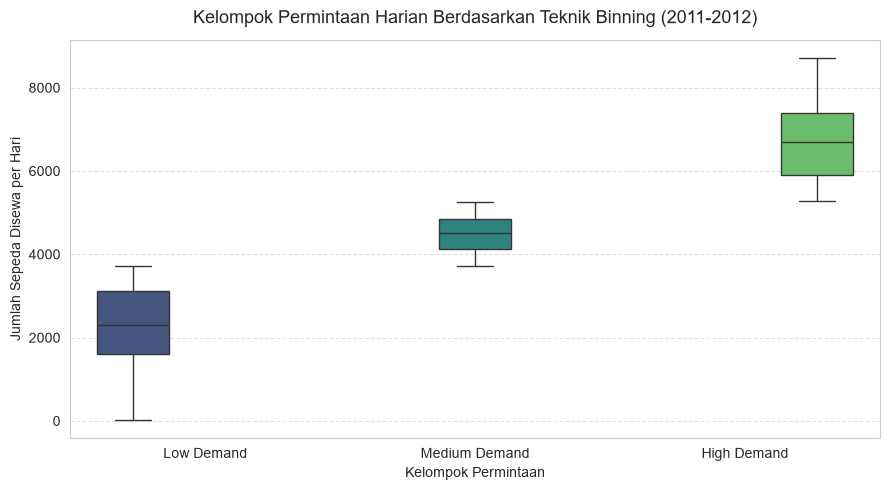

In [8]:
# Clustering manual dengan teknik binning: kelompokkan hari berdasarkan permintaan
q1, q3 = day_df['cnt'].quantile([0.33, 0.66])
bins = [0, q1, q3, day_df['cnt'].max()]
labels = ['Low Demand', 'Medium Demand', 'High Demand']
day_df['demand_level'] = pd.cut(day_df['cnt'], bins=bins, labels=labels, include_lowest=True)

print(f'Batas binning: 0 - {int(q1):,} - {int(q3):,} - {int(day_df["cnt"].max()):,}\n')

# Profil tiap klaster
profile = day_df.groupby('demand_level', observed=True).agg(
    jumlah_hari=('cnt', 'count'),
    rata_rata_cnt=('cnt', 'mean'),
    pct_akhir_pekan=('workingday', lambda x: 100 * (x == 0).mean()),
    rata_rata_atemp=('atemp', 'mean'),
    pct_cuaca_buruk=('weathersit', lambda x: 100 * (x >= 2).mean())
).round(1)
print(profile)

# Visualisasi: sebaran permintaan per kelompok
plt.figure(figsize=(9, 5))
sns.boxplot(data=day_df, x='demand_level', y='cnt', hue='demand_level',
            palette='viridis', legend=False, order=labels)
plt.title('Kelompok Permintaan Harian Berdasarkan Teknik Binning (2011-2012)', fontsize=13, pad=12)
plt.xlabel('Kelompok Permintaan')
plt.ylabel('Jumlah Sepeda Disewa per Hari')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Binning menghasilkan 3 kelompok dengan jumlah hari seimbang: **Low (241 hari, rata-rata 2.294/hari)**, **Medium (241 hari, 4.493/hari)**, dan **High (249 hari, 6.654/hari)**.
- **Cuaca adalah pembeda utama antar klaster**: 50,6% hari pada kelompok Low berstatus cuaca buruk/kabut, bandingkan hanya 24,5% di kelompok High.
- Kelompok High didominasi musim Fall (39%) dan hanya 4% dari hari kelompok High terjadi di musim semi; suhu nyaman (`atemp` rata-rata 0.6 vs 0.3 di Low) ikut mendorong permintaan tinggi.
- Pengguna *casual* makin dominan seiring naiknya permintaan: 14,5% (Low) → 20,6% (High), sedangkan hari akhir pekan justru lebih sering muncul di kelompok Low (37,8%).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Permintaan pada hari kerja terkonsentrasi pada dua jam sibuk komuter, yaitu pukul 17.00 (525 sepeda/jam) dan 08.00 (477 sepeda/jam), sedangkan pukul 10.00–15.00 hanya rata-rata 179 sepeda/jam. Artinya armada harus tersedia melimpah saat jam pulang-pergi kerja dan dapat ditarik untuk maintenance pada siang hari. Pada akhir pekan pola bergeser ke rekreasi dengan puncak pukul 13.00.
- **Conclusion pertanyaan 2:** Kondisi cuaca berpengaruh signifikan terhadap jumlah penyewaan harian: hari berkabut menurunkan permintaan 17,2% dan hari hujan ringan menurunkan permintaan 63,0% dibandingkan hari cerah, atau setara ±64.543 transaksi yang hilang pada 21 hari hujan ringan selama periode 2011–2012.
- **Conclusion analisis lanjutan (clustering binning):** Hari dengan permintaan rendah (241 hari) sangat dipengaruhi cuaca buruk (50,6% hari) dan musim semi, sementara permintaan tinggi terkonsentrasi di musim gugur dengan suhu nyaman — memvalidasi bahwa cuaca dan musim adalah dua faktor operasional terpenting dalam perencanaan armada.

**Rekomendasi Action Item:**
- **Redeployment armada dua kali sehari (tim operasional):** lakukan pengisian ulang sepeda di stasiun transit/permukiman pada pukul 05.00–07.00 dan 15.00–16.00 agar stok siap untuk puncak pagi (08.00) dan sore (17.00–18.00) hari kerja; kurangi perawatan pada jam sibuk, jadwalkan di pukul 02.00–05.00 saat permintaan di bawah 25 sepeda/jam.
- **Kampanye "Rainy Day Promo" (tim marketing):** sediakan potongan harga/voucher khusus hari hujan dan berkabut untuk menekan penurunan permintaan hingga 63%, targetkan pengguna *casual* yang paling sensitif terhadap cuaca.
- **Prioritaskan retensi pengguna langganan (tim bisnis):** karena 81,2% permintaan berasal dari pengguna *registered*, bangun program loyalitas berbasis musim (promosi awal musim semi yang rata-rata terendah, 2.604/hari) untuk menjaga pertumbuhan tahunan yang sudah +64,9%.
- **Kuota armada adaptif per kelompok permintaan (tim operasional):** berdasarkan clustering binning, siapkan armada penuh di 249 hari High Demand (musim gugur/cerah) dan terapkan *preventive maintenance* serta kurangi operasional pada hari kelompok Low yang 50,6% berpotensi cuaca buruk.

In [9]:
# Simpan data yang telah dibersihkan untuk digunakan pada dashboard
all_df = hour_df.merge(
    day_df[["dteday", "weathersit"]].rename(columns={"weathersit": "weather_day"}),
    on="dteday",
    how="left"
)
all_df.to_csv("all_data.csv", index=False)

print("all_data.csv tersimpan:", all_df.shape)

all_data.csv tersimpan: (17379, 20)
